# **Dataset Play Tennis Algoritma Naive Bayes & k-Nearest Neighbor (k-NN)**

## 4.1 Persiapan Lingkungan

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## 4.2 Load dan Eksplorasi Dataset Play Tennis

In [5]:
df = pd.read_csv(r'C:\Users\acer\Data Mining\Minggu 4\play_tennis.csv')
print (df.head())
print (df['PlayTennis'].value_counts())

  Day   Outlook Temperature Humidity    Wind PlayTennis
0  D1     Sunny         Hot     High    Weak         No
1  D2     Sunny         Hot     High  Strong         No
2  D3  Overcast         Hot     High    Weak        Yes
3  D4      Rain        Mild     High    Weak        Yes
4  D5      Rain        Cool   Normal    Weak        Yes
PlayTennis
Yes    9
No     5
Name: count, dtype: int64


## 4.3 Encoding Fitur Kategorikal

In [6]:
fitur = ['Outlook', 'Temperature', 'Humidity', 'Wind'] 
X = df[fitur].copy() 
y = df['PlayTennis'].copy() 
  
enc = OrdinalEncoder() 
X_enc = pd.DataFrame(enc.fit_transform(X), columns=fitur) 
for col, cats in zip(fitur, enc.categories_): 
    print(f'{col}: {dict(zip(cats, range(len(cats))))}')

Outlook: {'Overcast': 0, 'Rain': 1, 'Sunny': 2}
Temperature: {'Cool': 0, 'Hot': 1, 'Mild': 2}
Humidity: {'High': 0, 'Normal': 1}
Wind: {'Strong': 0, 'Weak': 1}


## 4.4 Membangun Model Naive Bayes pada Play Tennis 

In [7]:
clf_nb = CategoricalNB() 
clf_nb.fit(X_enc, y) 
  
for cls, logp in zip(clf_nb.classes_, clf_nb.class_log_prior_): 
    print(f'P({cls}) = {np.exp(logp):.4f}') 

P(No) = 0.3571
P(Yes) = 0.6429


## 4.5 Prediksi Data Baru dengan Naive Bayes 

In [8]:
data_baru = pd.DataFrame([{ 
    'Outlook': 'Sunny', 'Temperature': 'Cool', 
    'Humidity': 'High', 'Wind': 'Strong' 
}]) 
data_baru_enc = pd.DataFrame(enc.transform(data_baru), columns=fitur) 
  
pred = clf_nb.predict(data_baru_enc) 
proba = clf_nb.predict_proba(data_baru_enc) 
print('Prediksi:', pred[0]) 
print('Probabilitas:', dict(zip(clf_nb.classes_, proba[0].round(4)))) 

Prediksi: No
Probabilitas: {np.str_('No'): np.float64(0.7201), np.str_('Yes'): np.float64(0.2799)}


## 4.6 Naive Bayes pada Dataset Iris (Evaluasi dengan Train/Test Split)

In [9]:
iris = load_iris() 
Xi = pd.DataFrame(iris.data, columns=iris.feature_names) 
yi = iris.target 
  
Xi_train, Xi_test, yi_train, yi_test = train_test_split( 
    Xi, yi, test_size=0.3, random_state=42, stratify=yi) 
  
nb = GaussianNB() 
nb.fit(Xi_train, yi_train) 
nb_pred = nb.predict(Xi_test) 
  
print('Akurasi:', accuracy_score(yi_test, nb_pred)) 
print(classification_report(yi_test, nb_pred, target_names=iris.target_names, 
digits=3)) 

Akurasi: 0.9111111111111111
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.824     0.933     0.875        15
   virginica      0.923     0.800     0.857        15

    accuracy                          0.911        45
   macro avg      0.916     0.911     0.911        45
weighted avg      0.916     0.911     0.911        45



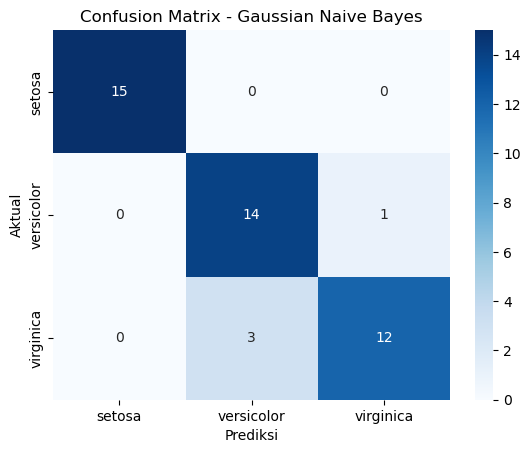

In [10]:
import seaborn as sns
cm = confusion_matrix(yi_test, nb_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - Gaussian Naive Bayes')
plt.show()

## 4.7 Membangun Model k-NN pada Dataset Iris

In [11]:
knn = KNeighborsClassifier(n_neighbors=5) 
knn.fit(Xi_train, yi_train) 
knn_pred = knn.predict(Xi_test) 
print('Akurasi:', accuracy_score(yi_test, knn_pred)) 
print(classification_report(yi_test, knn_pred, target_names=iris.target_names, 
digits=3))

Akurasi: 0.9777777777777777
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.938     1.000     0.968        15
   virginica      1.000     0.933     0.966        15

    accuracy                          0.978        45
   macro avg      0.979     0.978     0.978        45
weighted avg      0.979     0.978     0.978        45



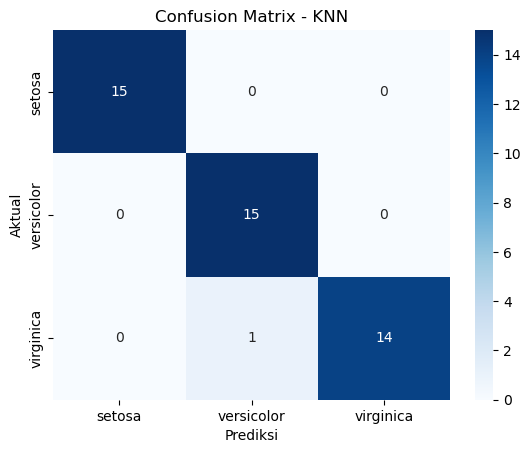

In [12]:
cm_knn = confusion_matrix(yi_test, knn_pred)

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - KNN')
plt.show()

In [13]:
# Prediksi data bunga baru

bunga_baru = pd.DataFrame([[5.0, 3.4, 1.5, 0.2]], columns=iris.feature_names) 
pred_bunga = knn.predict(bunga_baru) 
print('Prediksi kelas:', iris.target_names[pred_bunga[0]])

Prediksi kelas: setosa


## 4.8 Eksperimen: Pencarian Nilai k Optimal 

In [14]:
k_range = range(1, 21) 
k_scores = [] 
for k in k_range: 
    c = KNeighborsClassifier(n_neighbors=k) 
    c.fit(Xi_train, yi_train) 
    acc = accuracy_score(yi_test, c.predict(Xi_test)) 
    k_scores.append(acc) 
    print(f'k={k}: akurasi = {acc:.4f}') 

k=1: akurasi = 0.9333
k=2: akurasi = 0.9111
k=3: akurasi = 0.9556
k=4: akurasi = 0.9556
k=5: akurasi = 0.9778
k=6: akurasi = 0.9556
k=7: akurasi = 0.9556
k=8: akurasi = 0.9333
k=9: akurasi = 0.9556
k=10: akurasi = 0.9556
k=11: akurasi = 0.9333
k=12: akurasi = 0.9333
k=13: akurasi = 0.9333
k=14: akurasi = 0.9333
k=15: akurasi = 0.9556
k=16: akurasi = 0.9556
k=17: akurasi = 0.9556
k=18: akurasi = 0.9556
k=19: akurasi = 0.9556
k=20: akurasi = 0.9333


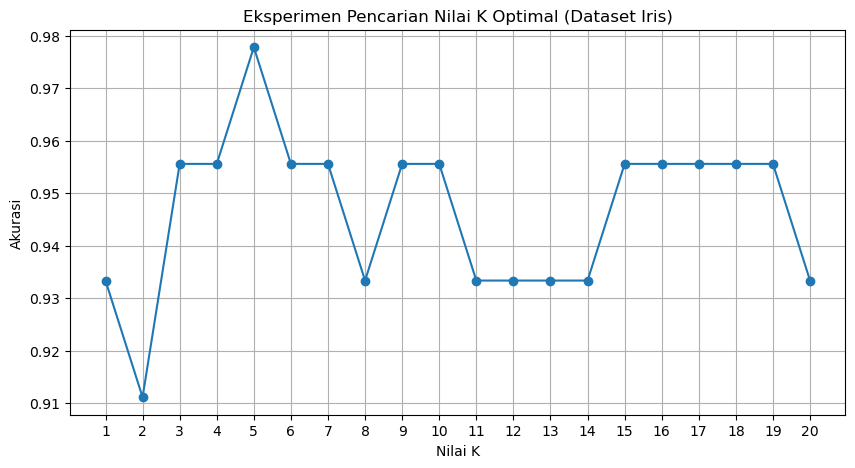

In [15]:
# Grafik akurasi KNN
plt.figure(figsize=(10, 5))
plt.plot(k_range, k_scores, marker='o', linestyle='-')

plt.title('Eksperimen Pencarian Nilai K Optimal (Dataset Iris)')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.xticks(list(k_range))
plt.grid(True)
plt.show()

## 4.9 Perbandingan Naive Bayes vs k-NN

In [16]:
print('Naive Bayes (Gaussian):', accuracy_score(yi_test, nb_pred)) 
print('k-NN (k=5):', accuracy_score(yi_test, knn_pred))

Naive Bayes (Gaussian): 0.9111111111111111
k-NN (k=5): 0.9777777777777777


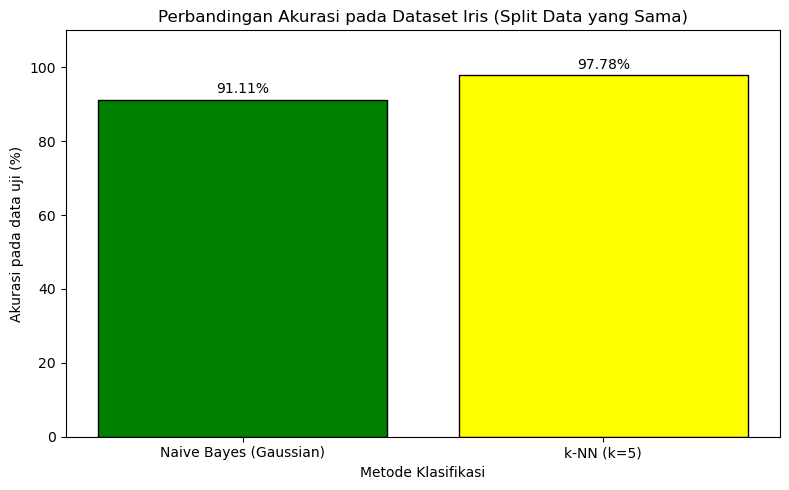

In [17]:
plt.figure(figsize=(8, 5))

akurasi = [
    accuracy_score(yi_test, nb_pred) * 100,
    accuracy_score(yi_test, knn_pred) * 100
]

bars = plt.bar(
    ['Naive Bayes (Gaussian)', 'k-NN (k=5)'],
    akurasi,
    color=['green', 'yellow'],
    edgecolor='black'
)

plt.title('Perbandingan Akurasi pada Dataset Iris (Split Data yang Sama)')
plt.xlabel('Metode Klasifikasi')
plt.ylabel('Akurasi pada data uji (%)')
plt.ylim(0, 110)

for bar, nilai in zip(bars, akurasi):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'{nilai:.2f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


## Tugas 1 a

In [18]:

from sklearn.preprocessing import OneHotEncoder
from sklearn.naive_bayes import BernoulliNB

# Encoding menggunakan OneHotEncoder
enc_oh = OneHotEncoder(handle_unknown='ignore')
X_oh = enc_oh.fit_transform(X)

# Membangun model BernoulliNB
clf_bern = BernoulliNB()
clf_bern.fit(X_oh, y)

# Prediksi data baru
data_baru_oh = enc_oh.transform(data_baru[fitur])

pred_bern = clf_bern.predict(data_baru_oh)
proba_bern = clf_bern.predict_proba(data_baru_oh)

print('Prediksi CategoricalNB:', pred[0])
print('Probabilitas CategoricalNB:',
      dict(zip(clf_nb.classes_, proba[0].round(4))))

print('\nPrediksi BernoulliNB:', pred_bern[0])
print('Probabilitas BernoulliNB:',
      dict(zip(clf_bern.classes_, proba_bern[0].round(4))))

print('\nApakah prediksi sama?', pred[0] == pred_bern[0])


Prediksi CategoricalNB: No
Probabilitas CategoricalNB: {np.str_('No'): np.float64(0.7201), np.str_('Yes'): np.float64(0.2799)}

Prediksi BernoulliNB: No
Probabilitas BernoulliNB: {np.str_('No'): np.float64(0.9101), np.str_('Yes'): np.float64(0.0899)}

Apakah prediksi sama? True


## Tugas 1 b

In [19]:
data_baru = pd.DataFrame({
    'Day': ['D15', 'D16', 'D17'],
    'Outlook': ['Sunny', 'Rain', 'Overcast'],
    'Temperature': ['Mild', 'Cool', 'Cool'],
    'Humidity': ['Normal', 'High', 'Normal'],
    'Wind': ['Weak', 'Strong', 'Weak'],
    'PlayTennis': ['Yes', 'No', 'Yes']
})

df = pd.concat([df, data_baru], ignore_index=True)

df

,Day,Outlook,Temperature,Humidity,Wind,PlayTennis
0,D1,Sunny,Hot,High,Weak,No
1,D2,Sunny,Hot,High,Strong,No
2,D3,Overcast,Hot,High,Weak,Yes
3,D4,Rain,Mild,High,Weak,Yes
4,D5,Rain,Cool,Normal,Weak,Yes
5,D6,Rain,Cool,Normal,Strong,No
6,D7,Overcast,Cool,Normal,Strong,Yes
7,D8,Sunny,Mild,High,Weak,No
8,D9,Sunny,Cool,Normal,Weak,Yes
9,D10,Rain,Mild,Normal,Weak,Yes


In [20]:
fitur = ['Outlook', 'Temperature', 'Humidity', 'Wind'] 
X = df[fitur].copy() 
y = df['PlayTennis'].copy() 
  
enc = OrdinalEncoder() 
X_enc = pd.DataFrame(enc.fit_transform(X), columns=fitur) 
for col, cats in zip(fitur, enc.categories_): 
    print(f'{col}: {dict(zip(cats, range(len(cats))))}')

Outlook: {'Overcast': 0, 'Rain': 1, 'Sunny': 2}
Temperature: {'Cool': 0, 'Hot': 1, 'Mild': 2}
Humidity: {'High': 0, 'Normal': 1}
Wind: {'Strong': 0, 'Weak': 1}


In [21]:
clf_nb = CategoricalNB() 
clf_nb.fit(X_enc, y) 
  
for cls, logp in zip(clf_nb.classes_, clf_nb.class_log_prior_): 
    print(f'P({cls}) = {np.exp(logp):.4f}') 

P(No) = 0.3529
P(Yes) = 0.6471


In [22]:
data_baru = pd.DataFrame([{ 
    'Outlook': 'Sunny', 'Temperature': 'Cool', 
    'Humidity': 'High', 'Wind': 'Strong' 
}]) 
data_baru_enc = pd.DataFrame(enc.transform(data_baru), columns=fitur) 
  
pred = clf_nb.predict(data_baru_enc) 
proba = clf_nb.predict_proba(data_baru_enc) 
print('Prediksi:', pred[0]) 
print('Probabilitas:', dict(zip(clf_nb.classes_, proba[0].round(4)))) 

Prediksi: No
Probabilitas: {np.str_('No'): np.float64(0.7968), np.str_('Yes'): np.float64(0.2032)}


## Tugas 2 a

In [23]:
# k-NN dengan jarak Euclidean (default)
knn_euclidean = KNeighborsClassifier(n_neighbors=5)
knn_euclidean.fit(Xi_train, yi_train)
pred_euclidean = knn_euclidean.predict(Xi_test)

acc_euclidean = accuracy_score(yi_test, pred_euclidean)

# k-NN dengan jarak Manhattan
knn_manhattan = KNeighborsClassifier(
    n_neighbors=5,
    metric='manhattan'
)
knn_manhattan.fit(Xi_train, yi_train)
pred_manhattan = knn_manhattan.predict(Xi_test)

acc_manhattan = accuracy_score(yi_test, pred_manhattan)

# Membandingkan akurasi
print(f'Akurasi Euclidean: {acc_euclidean:.4f}')
print(f'Akurasi Manhattan: {acc_manhattan:.4f}')

print('\nClassification Report - Manhattan')
print(classification_report(
    yi_test,
    pred_manhattan,
    target_names=iris.target_names,
    digits=3
))


Akurasi Euclidean: 0.9778
Akurasi Manhattan: 0.9333

Classification Report - Manhattan
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.833     1.000     0.909        15
   virginica      1.000     0.800     0.889        15

    accuracy                          0.933        45
   macro avg      0.944     0.933     0.933        45
weighted avg      0.944     0.933     0.933        45



In [24]:
# Data bunga baru
bunga_baru = pd.DataFrame(
    [[5.0, 3.4, 1.5, 0.2]],
    columns=iris.feature_names
)

# Prediksi dengan Euclidean
pred_euc = knn_euclidean.predict(bunga_baru)

print('Prediksi Euclidean:',
      iris.target_names[pred_euc[0]])

# Prediksi dengan Manhattan
pred_man = knn_manhattan.predict(bunga_baru)

print('Prediksi Manhattan:',
      iris.target_names[pred_man[0]])


Prediksi Euclidean: setosa
Prediksi Manhattan: setosa


## Tugas 2 b

In [25]:
from sklearn.preprocessing import StandardScaler

# 1. k-NN tanpa normalisasi
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(Xi_train, yi_train)
pred_asli = knn.predict(Xi_test)

acc_asli = accuracy_score(yi_test, pred_asli)

# 2. Normalisasi fitur menggunakan StandardScaler
scaler = StandardScaler()

Xi_train_scaled = scaler.fit_transform(Xi_train)
Xi_test_scaled = scaler.transform(Xi_test)

# 3. k-NN dengan normalisasi
knn_scaled = KNeighborsClassifier(n_neighbors=5)
knn_scaled.fit(Xi_train_scaled, yi_train)
pred_scaled = knn_scaled.predict(Xi_test_scaled)

acc_scaled = accuracy_score(yi_test, pred_scaled)

# 4. Perbandingan akurasi
print(f'Akurasi tanpa normalisasi: {acc_asli:.4f}')
print(f'Akurasi dengan normalisasi: {acc_scaled:.4f}')

if acc_scaled > acc_asli:
    print('Akurasi meningkat setelah normalisasi.')
elif acc_scaled < acc_asli:
    print('Akurasi menurun setelah normalisasi.')
else:
    print('Akurasi tetap sama setelah normalisasi.')


Akurasi tanpa normalisasi: 0.9778
Akurasi dengan normalisasi: 0.9111
Akurasi menurun setelah normalisasi.


## Tugas 3 a

In [35]:
df = pd.read_excel(r'C:\Users\acer\Data Mining\Minggu 6\Dataset_Mahasiswa_50.xlsx')
print(df.head())
print(df['Lulus'].value_counts())

  Mahasiswa  Jam_Belajar  Kehadiran  Tugas  UTS  Lulus
0        M1            2         75     65   60  Tidak
1        M2            3         80     70   65  Tidak
2        M3            1         70     60   55  Tidak
3        M4            5         90     80   75     Ya
4        M5            6         95     85   82     Ya
Lulus
Tidak    32
Ya       18
Name: count, dtype: int64


## Tugas 3 b

#### 1. Menyiapkan dataset dan fitur

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_mahasiswa = pd.read_excel(
    r'C:\Users\acer\Data Mining\Minggu 6\Dataset_Mahasiswa_50.xlsx'
)

fitur = ['Jam_Belajar', 'Kehadiran', 'Tugas', 'UTS']
X = df_mahasiswa[fitur]
y = df_mahasiswa['Lulus']

print("Jumlah data:", len(df_mahasiswa))
print("\nDistribusi target:")
print(y.value_counts())

Jumlah data: 50

Distribusi target:
Lulus
Tidak    32
Ya       18
Name: count, dtype: int64


#### 2. Membagi data dan menerapkan Naive Bayes

=== PEMBAGIAN DATA ===
Jumlah data latih: 35
Jumlah data uji: 15

=== EVALUASI NAIVE BAYES ===
Akurasi: 0.8
Confusion Matrix:
[[8 2]
 [1 4]]


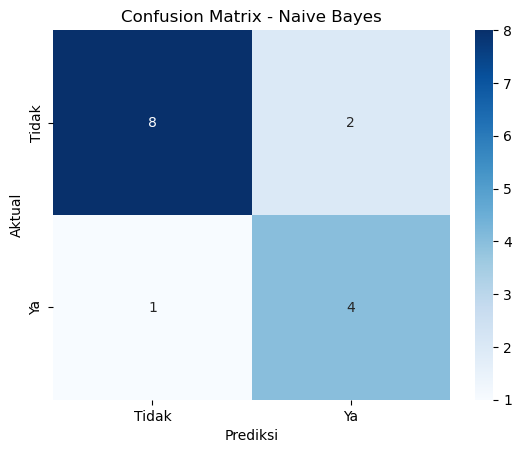

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("=== PEMBAGIAN DATA ===")
print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

# Melatih model Naive Bayes
nb = GaussianNB()
nb.fit(X_train, y_train)

# Melakukan prediksi
nb_pred = nb.predict(X_test)

# Evaluasi Naive Bayes
print("\n=== EVALUASI NAIVE BAYES ===")
print("Akurasi:", accuracy_score(y_test, nb_pred))

cm_nb = confusion_matrix(y_test, nb_pred, labels=['Tidak', 'Ya'])
print("Confusion Matrix:")
print(cm_nb)

sns.heatmap(
    cm_nb, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Tidak', 'Ya'],
    yticklabels=['Tidak', 'Ya']
)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - Naive Bayes')
plt.show()

#### 3. Menerapkan k-NN


=== EVALUASI K-NN ===
Akurasi: 0.7333333333333333
Confusion Matrix:
[[7 3]
 [1 4]]


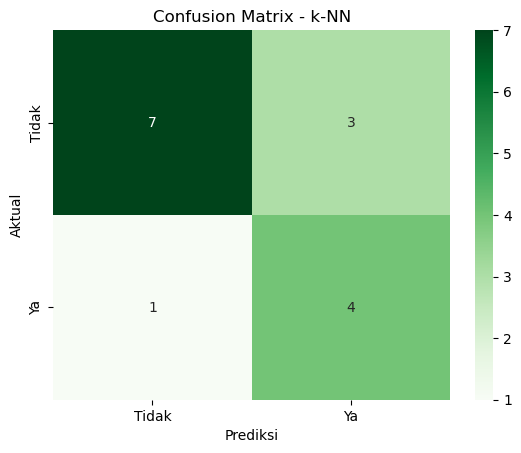

In [42]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Melatih model k-NN dengan k=5
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn.fit(X_train, y_train)

# Melakukan prediksi
knn_pred = knn.predict(X_test)

# Evaluasi k-NN
print("\n=== EVALUASI K-NN ===")
print("Akurasi:", accuracy_score(y_test, knn_pred))

cm_knn = confusion_matrix(y_test, knn_pred, labels=['Tidak', 'Ya'])
print("Confusion Matrix:")
print(cm_knn)

sns.heatmap(
    cm_knn, annot=True, fmt='d', cmap='Greens',
    xticklabels=['Tidak', 'Ya'],
    yticklabels=['Tidak', 'Ya']
)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - k-NN')
plt.show()

#### 4. Membandingkan hasil kedua algoritma

In [40]:
akurasi_nb = accuracy_score(y_test, nb_pred)
akurasi_knn = accuracy_score(y_test, knn_pred)

print(f'Akurasi Naive Bayes: {akurasi_nb:.4f}')
print(f'Akurasi k-NN: {akurasi_knn:.4f}')

if akurasi_nb > akurasi_knn:
    print("Naive Bayes lebih unggul berdasarkan akurasi.")
elif akurasi_knn > akurasi_nb:
    print("k-NN lebih unggul berdasarkan akurasi.")
else:
    print("Kedua algoritma memiliki akurasi yang sama.")

Akurasi Naive Bayes: 0.8000
Akurasi k-NN: 0.7333
Naive Bayes lebih unggul berdasarkan akurasi.
